## Tearing and coalescence of the Fadeev island chain, through the autodiff harness

**Rung 2b item 3 of `plans/AUTODIFF_PLAN.md`** -- the first 2D equilibrium: no $k_y$ block structure, so no 1D
eigencode can do this. The equilibrium is the Fadeev / Kelvin--Stuart chain of magnetic islands
$$\psi_0=\ln(\cosh x+\epsilon\cos y),\qquad 0\le\epsilon<1 ,$$
written in taranis's orientation: the sheet normal is $x$ (as in every 1D tearing notebook, $B_y(x)$, $k_y$ blocks) and
the chain runs along $y$ -- the usual form $\ln(\cosh y+\epsilon\cos x)$ with $x\leftrightarrow y$. $\boldsymbol b_\perp=\hat z\times\nabla\psi$,
so $B_y\to\tanh x$ as $\epsilon\to0$: the Harris sheet, half-width $a=1$, $v_A=1$, $S=1/\eta$, $\nu=0$, `hyper=1`, `dims=2`, fp64.
Normalised Alfvén units throughout.

Data: `examples/tearing_chain_run.py` (resumable, one cache file per solve under `examples/data/tearing-chain/`), gates:
`tests/test_tearing_chain.py`. This notebook only reads caches.

**What is computed.** (1) the coalescence instability of the chain against $\epsilon$ and $S$, and its ideal limit;
(2) the other period-doubling mode ("alternating") and the chain-period sector; (3) field-aligned flow $\phi_0=\alpha\psi_0$;
(4) the autodiff sensitivities $d\gamma/d\epsilon$ (state direction $dx_0=\partial x_0/\partial\epsilon$), $d\gamma/d\eta$
(overrides seam) and $d\gamma/d\alpha$, each against eigenvalue finite differences.

**Results** (every number printed below; $L_x=20$, $P$-mean of the two pair members, $S=10^3$ unless stated):

* **$\epsilon\to0$.** The $T=-1$ sector eigenvalues are the dense $k_y$-block eigenvalues of rung 1a's tanh pair to $10^{-12}$ (gate).
  The degenerate coalescence/alternating pair splits linearly, $\lambda=\lambda_0\pm c\epsilon$, with $c$ from ONE sensitivity at
  $\epsilon=0$: $c=0.780,\ 1.284,\ 2.019,\ 3.168$ at $S=10^2\ldots10^5$ (local exponent $\simeq0.20$). The linear regime ends at
  $\epsilon_*=\lambda_0/c$, where the island half-width is $w(\epsilon_*)\approx1.3$--$1.6\,\delta_\eta$ (sec. 4).
* **Coalescence.** One growing mode per sector, $\gamma$ increasing with $\epsilon$: $0.0250,\ 0.0762,\ 0.1261,\ 0.1586,\ 0.1673$ at
  $\epsilon=0.01,0.1,0.3,0.6,0.75$ (production grid; an independent single-sheet eigencode, sec. 7b, gives
  $0.0762,\ 0.1262,\ 0.1584,\ 0.1671$ at $\epsilon=0.1\ldots0.75$ -- the production numbers are good to $1.3\times10^{-3}$). The autodiff exponent $s_S=d\ln\gamma/d\ln S$ is $-0.521$ at $\epsilon=0$ (resistive tearing) and
  $-0.042\ldots-0.018$ for $\epsilon\ge0.2$: **nearly ideal** -- the coalescence instability of Finn & Kaw. $s_\epsilon=d\ln\gamma/d\ln\epsilon
  \approx0.5$ at $\epsilon=0.03$--$0.1$ **at $S=10^3$ only** -- it is not a $\gamma\propto\sqrt\epsilon$ law: the same exponent is
  $\le0.40$ at $S=10^2$ and rises with $S$ ($\epsilon=0.03$: $0.50,\ 0.63,\ 0.70$ at $S=10^3,10^4,10^5$, sec. 7b), towards
  Bondeson's (1983) ideal small-island law $\gamma\propto w^{3/2}\propto\epsilon^{3/4}$; it falls to $0.20$ at $\epsilon=0.75$. Matrix-free at
  $S=10^4$, $\epsilon=0.3$: $0.1218$ (independent route: $0.1219$) ($512\times256$, $768\times256$, $512\times384$ within $7\times10^{-4}$); the approach to the ideal
  limit is slower than a single power law fitted to $S=10^2,10^3$ and $s_S$ predicts.
* **Alternating** ($R=-1$) mode: born with coalescence at $\epsilon=0$, stabilised by $\epsilon=0.3$ at $S=10^2$ and $10^3$ (the $\sim10^{-5}$ residual growth at $\epsilon=0.2$,
  $S=10^3$ and the $10^{-9}$ at $\epsilon=0.3$, $S=10^2$ are grid artefacts: zero on $384\times128$ resp. $384\times64$).
  **Chain-period sector** ($T=+1$): nothing but a box artefact (a relative sliding of the two chains, $\gamma$ falls 16$\times$ from
  $L_x=20$ to 30, as $e^{-L_x/4}$ -- the square root of the $k=1$ inter-chain coupling $e^{-L_x/2}$ -- and is zero at $L_x=40,50$ on
  resolved grids).
* **Field-aligned flow** $\phi_0=\alpha\psi_0$ ($\epsilon=0.3$) suppresses coalescence to zero as $\alpha\to1$, roughly like $1-\alpha^2$ but
  **above** it: production grid $\gamma(\alpha)/\gamma(0)=0.963,\,0.850,\,0.657,\,0.378,\,0.203$ at $\alpha=0.2\ldots0.9$, resolved
  (independent route, sec. 8b) $0.964,\,0.856,\,0.671,\,0.400,\,0.226$, against $1-\alpha^2=0.96,\,0.84,\,0.64,\,0.36,\,0.19$ -- the excess
  grows to 11% at $\alpha=0.8$ and 19% at $0.9$, and shrinks with $S$ ($\alpha=0.6$, resolved: $0.705,\ 0.671,\ 0.653$ at
  $S=10^2,10^3,10^4$). Not an exact law (sec. 8). The production $256\times128$ grid is 2% low at $\alpha=0.6$, 6% at $0.8$, 10% at $0.9$
  (the $n_x$ resolution: $512\times128$ moves $\alpha=0.6$ by $+1.4\%$).
* **Autodiff checked.** $d\gamma/d\epsilon$ (state direction), $d\gamma/d\eta$ (overrides seam) and $d\gamma/d\alpha$ agree with
  Richardson-extrapolated eigenvalue finite differences to $3\times10^{-7}$--$7\times10^{-11}$ relative.
* **Independent route.** Two nonlinear solver runs (no jvp, no eigensolver) at $\eta=0$ give the frozen-$x_0$ eigenvalue to
  $1.8\times10^{-3}$; at $S=10^4$ they fall 1% below it, the resistive decay of the base state that the frozen linearisation ignores.
* **Independent eigencode** (sec. 7b; no taranis code: one isolated sheet between walls, mapped FD in $x$, Galerkin in $y$):
  $\gamma=0.126205$ at $S=10^3$, $\epsilon=0.3$, converged to $10^{-6}$. The $512\times256$ $P$-mean is $0.126213$ ($6\times10^{-5}$);
  the two members alone are $-2.9\%$ / $+2.9\%$ off. This is what justifies reporting the $P$-mean (sec. 2).
* **Convergence** ($S=10^3$): $n_x$, $n_y$ doubled and $L_x=20,30,40$ all within $2.5\times10^{-3}$ of the production numbers.

In [1]:
import os
os.environ["TARANIS_PRECISION"] = "64"
import numpy as np
import matplotlib.pyplot as plt
import taranis as jr
import tearing_chain_run as C

# reference palette, fixed order (dataviz skill): blue, orange, aqua, yellow
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "lines.linewidth": 2, "lines.markersize": 6})
ET = {S: C.eps_table(S) for S in C.S_LIST}
print({S: len(v) for S, v in ET.items()}, "eps points per S read from", C.DATA_ROOT)

field variables are using 64bit precision.
{100.0: 9, 1000.0: 9} eps points per S read from /Users/alfy/code/taranis/examples/data/tearing-chain


### 1. The equilibrium

With $D=\cosh x+\epsilon\cos y$: $\psi_{xx}=\cosh x/D-\sinh^2x/D^2$, $\psi_{yy}=-\epsilon\cos y/D-\epsilon^2\sin^2y/D^2$, and since
$(\cosh x-\epsilon\cos y)D-\sinh^2x-\epsilon^2\sin^2y=1-\epsilon^2$,
$$\nabla^2\psi_0=\frac{1-\epsilon^2}{D^2}=(1-\epsilon^2)\,e^{-2\psi_0}=F(\psi_0)\quad\Rightarrow\quad\{\psi_0,\nabla^2\psi_0\}=0 ,$$
an exact steady state of ideal 2D RMHD, and $\phi_0=G(\psi_0)$ keeps it steady for any $G$ (both brackets vanish; for $G=\alpha\psi_0$
the vorticity equation's $\alpha^2\{\psi_0,J_0\}-\{\psi_0,J_0\}=0$). Geometry: X-points at $(0,2\pi m)$, O-points at
$(0,\pi+2\pi m)$, chain period $2\pi$; the separatrix is $\psi_0=\ln(1+\epsilon)$, so the island half-width on the O-point line is
$w=\operatorname{arccosh}(1+2\epsilon)\to2\sqrt\epsilon$; the current is $(1+\epsilon)/(1-\epsilon)$ at the O-point and
$(1-\epsilon)/(1+\epsilon)$ at the X-point. As $\epsilon\to0$, $\psi_0=\ln\cosh x+\epsilon\,\mathrm{sech}\,x\cos y+O(\epsilon^2)$: the
chain is the finite-amplitude continuation of the **marginal** $k=1$ Harris tearing eigenfunction $\mathrm{sech}\,x\cos y$
($\Delta'(k=1)=0$).

**Periodic box, two sheets.** taranis is periodic in $x$ too. $\psi_0=\psi_{pair}(x)+\sum_{\rm images}[h(x-L_x/4,y)-h(x-3L_x/4,y)]$
with $h=\ln(1+\epsilon\cos y/\cosh u)$ (the chain minus its Harris part, $\simeq2\epsilon e^{-|u|}\cos y$) and $\psi_{pair}$ the
exact tanh pair of rung 1b-ref: near each sheet $\psi_0$ is the chain (sheet 2: minus the chain) up to $O(\epsilon e^{-L_x/2})$.
$L_y=4\pi$ holds **two** chain periods, so the period-doubling modes (coalescence) fit. The discrete $N(x_0)$ (the solver's own
dealiased RHS) is round-off at $L_x=40$; at the production box $L_x=20$ it is the image coupling $\sim e^{-L_x/2}$, and at small
$n_y$ the spectral truncation of the non-band-limited chain (analytic in a strip of width $\operatorname{arccosh}(1/\epsilon)$ in $y$):

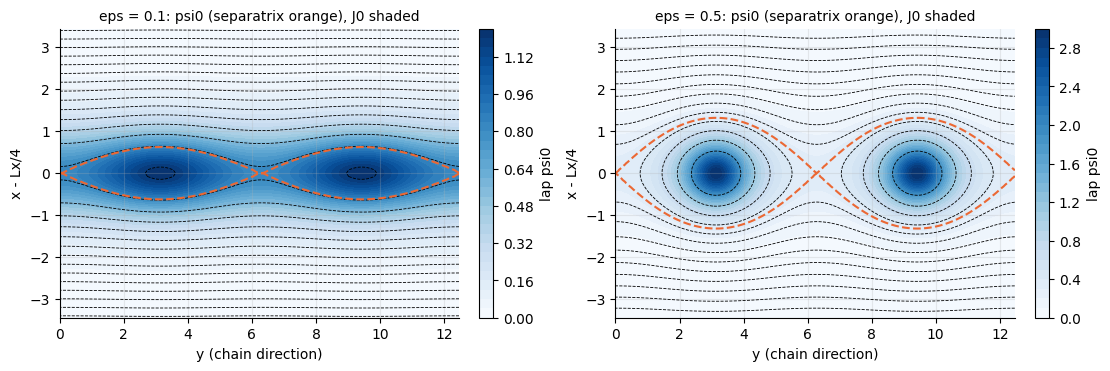

island half-width w(eps) and O-point current:
  eps= 0.01: w = 0.1997 (2 sqrt(eps) = 0.2000), J_O = 1.020
  eps=  0.1: w = 0.6224 (2 sqrt(eps) = 0.6325), J_O = 1.222
  eps=  0.3: w = 1.0470 (2 sqrt(eps) = 1.0954), J_O = 1.857
  eps=  0.6: w = 1.4254 (2 sqrt(eps) = 1.5492), J_O = 4.000
  eps= 0.75: w = 1.5668 (2 sqrt(eps) = 1.7321), J_O = 7.000

|N(x0)|/|x0| (k space), eps = 0.3:
  Lx=  20 256x64: 2.47e-06
  Lx=  30 384x64: 7.10e-09
  Lx=  40 512x64: 2.73e-11
  Lx=  20 256x16: 2.33e-05
  Lx=  20 256x128: 2.47e-06


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
p = C.make_params(1e3, 256, 128, Lx=C.LX0)
x, y = C.grid(p)
for a_, eps in zip(ax, (0.1, 0.5)):
    ps = C.psi_chain(x, y, C.LX0, eps)
    J = C.chain_current(x - C.LX0/4, y, eps)
    sel = np.abs(x - C.LX0/4) < 3.5
    m = a_.contourf(y, x[sel] - C.LX0/4, J[sel], 30, cmap="Blues")
    a_.contour(y, x[sel] - C.LX0/4, ps[sel], 14, colors="k", linewidths=0.6)
    a_.contour(y, x[sel] - C.LX0/4, ps[sel], [ps[np.argmin(np.abs(x - C.LX0/4)), 0]], colors=COL[1], linewidths=1.5)
    a_.set_xlabel("y (chain direction)"); a_.set_ylabel("x - Lx/4")
    a_.set_title(f"eps = {eps}: psi0 (separatrix orange), J0 shaded", fontsize=10)
    plt.colorbar(m, ax=a_, label="lap psi0")
plt.show()
print("island half-width w(eps) and O-point current:")
for e in (0.01, 0.1, 0.3, 0.6, 0.75):
    print(f"  eps={e:5}: w = {C.island_halfwidth(e):.4f} (2 sqrt(eps) = {2*np.sqrt(e):.4f}), J_O = {C.current_O(e):.3f}")
print("\n|N(x0)|/|x0| (k space), eps = 0.3:")
for Lx, nx, ny in ((20.0, 256, 64), (30.0, 384, 64), (40.0, 512, 64), (20.0, 256, 16), (20.0, 256, 128)):
    pp = C.make_params(1e3, nx, ny, Lx=Lx)
    print(f"  Lx={Lx:4g} {nx}x{ny}: {C.n_of_x0(pp, C.make_x0(pp, 0.3)):.2e}")

### 2. Symmetries, sectors, and which pair member

Every map below commutes with $J$ exactly (gated on random vectors in `test_symmetries_commute`); on $(\phi,\psi)$:

| map | action | Fourier (rfft2) | role |
|---|---|---|---|
| $T$ | $y\to y+2\pi$ | $(-1)^{i_{k_y}}$ on $L_y=4\pi$ | Bloch: $T=+1$ chain period ($i_{k_y}$ even), $T=-1$ **period doubling** ($i_{k_y}$ odd) |
| $R$ | $(\phi,\psi)\to(-\phi,\psi)(x,-y)$ | $\hat g(k_x,k_y)=\overline{\hat f(-k_x,k_y)}$, $\phi$ sign flip | $R=+1$: $\psi_1$ even, $\phi_1$ odd about the X-point $y=0$ |
| $P$ | $(\phi,\psi)\to(\phi,-\psi)(x-L_x/2,y)$ | $(-1)^{i_{k_x}}$, $\psi$ sign flip | the two sheets in phase / anti-phase |
| $XR$ | $(\phi,\psi)\to(\phi,\psi)(L_x/2-x,-y)$ | $(-1)^{i_{k_x}}\overline{\hat f}$ | rotation by $\pi$ about an X-point |

(the bracket changes sign under one reflection, hence $\phi\to-\phi$ in $R$; RMHD is even in $\psi$, hence $P$.) With flow
$\phi_0=\alpha\psi_0$, $R$ and $P$ each map $\alpha\to-\alpha$; $PR$ and $XR$ survive. In the $T=-1$ sector at $\epsilon=0$ the
$k_y=1/2$ tearing mode is a degenerate $\cos/\sin$ pair: $R$ splits it into **coalescence** ($R=+1$: $\phi_1$ odd about the X-point,
the islands at $y=\pm\pi$ move in opposite directions, i.e. towards or away from the X-point between them) and **alternating**
($R=-1$: $\psi_1$ odd about the X-point = even about the O-points, one island gains the flux its neighbours lose).

**Pair member.** Two sheets per box: each mode comes as a $P=\pm1$ pair, split by the outer-region coupling $\sim e^{-kL_x/2}$.
We solve **both** members and report their **mean** as the isolated-sheet value: the coupling enters the two members with opposite
sign at first order. The 1D $\epsilon=0$ check of that rule (dense $k_y$ block, $\Delta x$ fixed): the members split 6.8% at $L_x=20$
but the mean moves by only $2$--$4\times10^{-4}$ relative between $L_x=20$ and $60$ (table below), while the faster member alone is
3.2% high. The mean of two eigenvalues is not itself an eigenvalue: it is an **estimator** of the isolated-sheet eigenvalue, exact to
first order in the coupling. At finite $\epsilon$ it is checked two ways: the $L_x=20/30/40$ box scan (sec. 7: means within
$1.5\times10^{-3}$, splits 6.3%, 1.6%, 0.03%) and an independent single-sheet eigencode with no images at all (sec. 7b), which the
resolved $L_x=20$ $P$-mean matches to $6\times10^{-5}$ at $S=10^3$, $\epsilon=0.3$. Both members are printed wherever a growth rate is
tabulated; quote the mean, with the split, as the isolated-chain value.

**Coordinates.** A sector is an orthonormal real basis $E$ (`sector_basis`) of the joint eigenspace inside the Bloch sector's real
coordinates (`stability.real_coords` restricted to the $T$-sector's $i_{k_y}$); every solve works with $E^TJE$, exact because the maps
commute with $J$. A $(T,R,P)$ sector is 1/8 of the real coordinates.

In [3]:
from taranis import stability as st
print("eps = 0, 1D ky block (k = 1/2) of the tanh pair: members, mean, split, at fixed dx = 0.039 (Lx 20/40/60)")
for S in (1e2, 1e3):
    for Lx, nx in ((20.0, 512), (40.0, 1024), (60.0, 1536)):
        pp = C.make_params(S, nx, 8, Lx=Lx)
        B, _ = st.ky_block_matrix(C.make_x0(pp, 0.0), jr.setup_kgrids(pp), pp, 1)
        v = np.sort(st.eig_dense(B).values.real)[::-1][:2]
        print(f"  S={S:5g} Lx={Lx:4g}: {v[0]:.7f} {v[1]:.7f}  mean {v.mean():.8f}  split {(v[0]-v[1])/v.mean():.2e}")
pp = C.make_params(1e3, 256, 128, Lx=C.LX0)
kg = jr.setup_kgrids(pp)
print("\nsector sizes at the S = 1e3 production grid 256x128:",
      {C.Sector(kg, pp, t, sg).label(): C.Sector(kg, pp, t, sg).m for t in (-1, 1) for sg in ({"R": 1, "P": 1}, {"PR": 1, "XR": 1})},
      " (real coordinates:", st.real_coords(kg, pp).n, ")")
p5 = C.make_params(1e3, 512, 256, Lx=C.LX0)
print("... and at 512x256:", C.Sector(jr.setup_kgrids(p5), p5, -1, {"R": 1, "P": 1}).m)

eps = 0, 1D ky block (k = 1/2) of the tanh pair: members, mean, split, at fixed dx = 0.039 (Lx 20/40/60)
  S=  100 Lx=  20: 0.0397435 0.0371382  mean 0.03844082  split 6.78e-02
  S=  100 Lx=  40: 0.0384412 0.0384236  mean 0.03843241  split 4.57e-04
  S=  100 Lx=  60: 0.0384325 0.0384324  mean 0.03843241  split 3.08e-06
  S= 1000 Lx=  20: 0.0135533 0.0127080  mean 0.01313064  split 6.44e-02
  S= 1000 Lx=  40: 0.0131286 0.0131229  mean 0.01312572  split 4.34e-04
  S= 1000 Lx=  60: 0.0131257 0.0131257  mean 0.01312572  split 2.90e-06

sector sizes at the S = 1e3 production grid 256x128: {'T-P+R+': 2857, 'T-PR+XR+': 2836, 'T+P+R+': 2863, 'T+PR+XR+': 2842}  (real coordinates: 22878 )
... and at 512x256: 11447


### 3. Solvers and cost

* **Dense** (`sector_dense`): $E^TJE$ by one jvp per column, `eig_dense` (right and left vectors) -- the whole sector spectrum, so
  "fastest mode" and the isolation test of `eigenvalue_sensitivity` are complete. Used for every scan point and every sensitivity.
* **Matrix-free** (`sector_eigs`): ARPACK on $E^Te^{JT}E$, $e^{JT}$ by `stability.propagator_operator` (the solver's own lsrk54 on the
  linearised system), with `propagator_eigs`' checks copied (Rayleigh branch, residual on $J$ itself, RuntimeError above $10^{-4}$;
  with no signs it reproduces `propagator_eigs` to $10^{-12}$, gated). Used where dense does not fit: the $512\times256$,
  $768\times256$ and $512\times384$ convergence points.
* **Only $k=1$ per sector works matrix-free.** With $\nu=0$ every sector carries a cluster of neutral or barely damped eigenvalues
  (flows along flux surfaces $\delta\phi=g(\psi_0)$ are exactly steady at $\nu=0$, plus the weakly damped Alfvén continuum), i.e. a
  cluster of $|\mu|\simeq1$ in $e^{JT}$: asking ARPACK for a second eigenvalue in a sector with one growing mode reaches into it and
  does not converge (measured: $k=2$ ran $>45$ min without converging where $k=1$ took 13 applications). One growing mode per
  sector is what the dense spectra show (`n_grow` below), so $k=1$ loses nothing here. (With $k=1$ ARPACK returns the largest
  $|e^{\lambda T}|$, i.e. the fastest mode of the sector whatever else grows; the labelling relies on the dense spectra. The counts hold
  for every cached dense record, including $\alpha\le0.9$ and the $S=10^4$, $256\times128$ point; only a sector with the $XR$ label dropped
  -- $(T,PR)=(-,+)$, $\alpha=0.6$ -- shows a second, overstable pair at $\gamma=1.5\times10^{-5}\ll\eta$.)
* **The preconditioned GMRES route is not used**, per rung 0b ($\epsilon\gtrsim0.1$ defeats the ky-averaged preconditioner,
  $(L-\sigma)^{-1}$ is useless at $\nu=0$). The symmetry reduction is what makes dense the cheaper route at production size
  (a $T,R,P$ sector at $256\times128$ is $m\approx2900$: 1--2 min dense on the loaded laptop, the same as a $k=1$ propagator
  solve of that sector -- 148--282 s for the $P$ pair, sec. 7 -- and dense also returns the left vectors and the whole spectrum). The propagator is
  the only route at $512\times256$ ($m\approx11500$; 475--1609 s per $P$ pair, sec. 7).

### 4. $\epsilon\to0$: the Harris $k_y=1/2$ tearing mode and its first-order splitting

At $\epsilon=0$, $x_0$ is the tanh pair and the $T=-1$ sector at $i_{k_y}=1$ is the $k=1/2$ Harris tearing mode ($\Delta'a=3$):
the sector eigenvalues equal the dense $k_y$-block eigenvalues of rung 1a's own tanh-pair state to $10^{-12}$ (gate
`test_eps0_is_the_harris_pair_ky_block`), $R=\pm1$ degenerate.

$\partial J/\partial\epsilon$ at $\epsilon=0$ carries only $\cos y$ ($\partial_\epsilon\psi_0=\mathrm{sech}\,x\cos y$), so it couples
$k_y=+1/2$ to $-1/2$ and has no diagonal part in the degenerate pair: first-order degenerate perturbation theory gives a $2\times2$
matrix $\begin{pmatrix}0&c\\c&0\end{pmatrix}$ and
$$\lambda_{R=\pm1}(\epsilon)=\lambda_0\pm c\,\epsilon+O(\epsilon^2),$$
which the harness gives directly: in each $R$ sector the eigenvalue is simple, so `eigenvalue_sensitivity` applies at $\epsilon=0$
and returns $\pm c$ (opposite to $10^{-9}$ relative, gated). Coalescence ($R=+1$) is the one that grows.

In [4]:
print("eps = 0: lam0 (P-mean), c = d lam(R+)/d eps, d lam(R-)/d eps; Harris layer-relation gamma; eps* = lam0/c; w(eps*); delta_eta")
SP = C.split_table()
for r in SP:
    S = r["S"]
    es = r["lam0"]/r["c"]
    de = (1/S/0.5)**(1/3)
    print(f"  S={S:6.0e} (nx {C.SPLIT_NX[S]}): lam0 = {r['lam0']:.6e}  c = {r['c']:+.5f}  c(R-) = {r['c_minus']:+.5f}  "
          f"gamma_Harris = {C.gamma_harris(S):.4e}  eps* = {es:.3e}  w(eps*) = {C.island_halfwidth(es):.4f}  "
          f"delta_eta = {de:.4f}  w/delta = {C.island_halfwidth(es)/de:.2f}")
Ss = np.array([r["S"] for r in SP]); cs = np.array([r["c"] for r in SP])
print("local exponents d ln c/d ln S:", np.round(np.diff(np.log(cs))/np.diff(np.log(Ss)), 4))

eps = 0: lam0 (P-mean), c = d lam(R+)/d eps, d lam(R-)/d eps; Harris layer-relation gamma; eps* = lam0/c; w(eps*); delta_eta
  S= 1e+02 (nx 512): lam0 = 3.844082e-02  c = +0.78047  c(R-) = -0.78047  gamma_Harris = 5.2590e-02  eps* = 4.925e-02  w(eps*) = 0.4403  delta_eta = 0.2714  w/delta = 1.62
  S= 1e+03 (nx 512): lam0 = 1.313064e-02  c = +1.28359  c(R-) = -1.28359  gamma_Harris = 1.4669e-02  eps* = 1.023e-02  w(eps*) = 0.2019  delta_eta = 0.1260  w/delta = 1.60
  S= 1e+04 (nx 1024): lam0 = 3.699501e-03  c = +2.01938  c(R-) = -2.01938  gamma_Harris = 3.8557e-03  eps* = 1.832e-03  w(eps*) = 0.0856  delta_eta = 0.0585  w/delta = 1.46
  S= 1e+05 (nx 2048): lam0 = 9.713178e-04  c = +3.16827  c(R-) = -3.16827  gamma_Harris = 9.8673e-04  eps* = 3.066e-04  w(eps*) = 0.0350  delta_eta = 0.0271  w/delta = 1.29
local exponents d ln c/d ln S: [0.2161 0.1968 0.1956]


S = 1000 (512x32, dense): eps, coalescence (R+) and alternating (R-) P-means, linear prediction lam0 +- c eps
  eps=0.0e+00: R+ 1.313064e-02 (lam0 + c eps = 1.313064e-02)   R- +1.313064e-02 (lam0 - c eps = +1.313064e-02)   d lam(R+)/d eps = 1.2836
  eps=1.0e-03: R+ 1.443188e-02 (lam0 + c eps = 1.441423e-02)   R- +1.188297e-02 (lam0 - c eps = +1.184705e-02)   d lam(R+)/d eps = 1.3107
  eps=3.0e-03: R+ 1.702225e-02 (lam0 + c eps = 1.698142e-02)   R- +9.739045e-03 (lam0 - c eps = +9.279867e-03)   d lam(R+)/d eps = 1.2656
  eps=1.0e-02: R+ 2.490225e-02 (lam0 + c eps = 2.596656e-02)   R- +5.742630e-03 (lam0 - c eps = +2.947264e-04)   d lam(R+)/d eps = 1.0023
  eps=3.0e-02: R+ 4.124128e-02 (lam0 + c eps = 5.163838e-02)   R- +2.537308e-03 (lam0 - c eps = -2.537710e-02)   d lam(R+)/d eps = 0.6880
S = 10000 (1024x32, dense): eps, coalescence (R+) and alternating (R-) P-means, linear prediction lam0 +- c eps
  eps=0.0e+00: R+ 3.699501e-03 (lam0 + c eps = 3.699501e-03)   R- +3.699501e-03 (lam0 - 

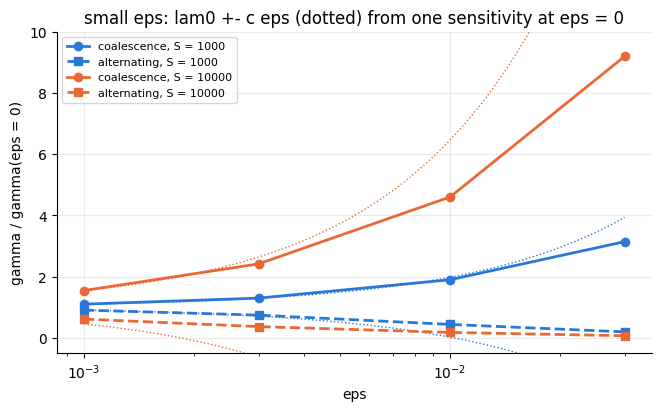

In [5]:
SM = {S: C.small_table(S) for S in C.SMALL_GRID}
for S, rows in SM.items():
    g = C.SMALL_GRID[S]
    print(f"S = {S:g} ({g[0]}x{g[1]}, dense): eps, coalescence (R+) and alternating (R-) P-means, linear prediction lam0 +- c eps")
    lam0, c0 = rows[0]["plus"], rows[0]["d_plus"]
    for r in rows:
        print(f"  eps={r['eps']:7.1e}: R+ {r['plus']:.6e} (lam0 + c eps = {lam0 + c0*r['eps']:.6e})   "
              f"R- {r['minus']:+.6e} (lam0 - c eps = {lam0 - c0*r['eps']:+.6e})   d lam(R+)/d eps = {r['d_plus']:.4f}")
fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
for i, (S, rows) in enumerate(SM.items()):
    e = np.array([r["eps"] for r in rows]); gp = np.array([r["plus"] for r in rows]); gm = np.array([r["minus"] for r in rows])
    ax.plot(e[1:], gp[1:]/gp[0], "o-", color=COL[i], label=f"coalescence, S = {S:g}")
    ax.plot(e[1:], gm[1:]/gp[0], "s--", color=COL[i], label=f"alternating, S = {S:g}")
    ee = np.geomspace(e[1], e[-1], 50)
    ax.plot(ee, 1 + rows[0]["d_plus"]*ee/gp[0], ":", color=COL[i], lw=1)
    ax.plot(ee, 1 - rows[0]["d_plus"]*ee/gp[0], ":", color=COL[i], lw=1)
ax.set_xscale("log"); ax.set_xlabel("eps"); ax.set_ylabel("gamma / gamma(eps = 0)")
ax.set_ylim(-0.5, 10); ax.legend(fontsize=8); ax.set_title("small eps: lam0 +- c eps (dotted) from one sensitivity at eps = 0")
plt.show()

### 5. Coalescence against $\epsilon$ and $S$: the ideal limit, from one sensitivity per point

Dense $(T,R,P)=(-,+,\pm)$ sectors at $L_x=20$, $S=10^2$ ($256\times64$) and $S=10^3$ ($256\times128$); the $P$-mean is reported.
Every point also gives $d\gamma/d\epsilon$ (state direction $dx_0=\partial x_0/\partial\epsilon$, built analytically:
$\partial_\epsilon\psi_0=\cos y/(\cosh x+\epsilon\cos y)$, gated against FD) and $d\gamma/d\eta$ (`dparams={"diss": (0, 1)}`), hence
two **local exponents** with no second solve:
$$s_\epsilon=\frac{d\ln\gamma}{d\ln\epsilon}=\frac{\epsilon}{\gamma}\frac{d\gamma}{d\epsilon},\qquad
s_S=\frac{d\ln\gamma}{d\ln S}=-\frac{\eta}{\gamma}\frac{d\gamma}{d\eta}.$$
$s_S\to0$ is the ideal limit. The resistive decay of $x_0$ ($\eta\nabla^2\psi_0\ne0$) is ignored: $x_0$ is frozen, as in every 1D
notebook -- the linearisation is instantaneous, meaningful for $\gamma\gg\eta J_0$.

In [6]:
for S, rows in ET.items():
    print(f"S = {S:g}, grid {C.GRID[S]}: eps | gamma(P+) gamma(P-) | mean | s_eps | s_S | #growing per sector | kappa")
    for r in rows:
        se = r["eps"]*r["d_eps"]/r["mean"]
        sS = -r["d_eta"]/S/r["mean"]
        print(f"  {r['eps']:5.2f} | {r['lam_p'].real:.6f} {r['lam_m'].real:.6f} | {r['mean']:.6f} | {se:6.3f} | {sS:+.4f} | "
              f"{r['n_grow']} | {r['kappa_eps'][0]:.1f}")
print("\nideal extrapolation gamma = g_inf + a S^-q from gamma(1e2), gamma(1e3) and s_S(1e3); check: predicted vs computed s_S(1e2)")
XT = {}
for r1, r2 in zip(ET[1e2], ET[1e3]):
    g_inf, q, e1p = C.ideal_extrapolation(r1["mean"], r2["mean"], -r2["d_eta"]/1e3/r2["mean"])
    XT[r1["eps"]] = (g_inf, q)
    print(f"  eps={r1['eps']:5.2f}: g_inf = {g_inf:.4f}  q = {q:.3f}  s_S(1e2) predicted {e1p:+.4f}, computed {-r1['d_eta']/1e2/r1['mean']:+.4f}")

S = 100, grid (256, 64): eps | gamma(P+) gamma(P-) | mean | s_eps | s_S | #growing per sector | kappa
   0.00 | 0.037138 0.039743 | 0.038441 |  0.000 | -0.3888 | (1, 1) | 4.3
   0.01 | 0.044803 0.047558 | 0.046180 |  0.164 | -0.2844 | (1, 1) | 4.3
   0.03 | 0.058478 0.061592 | 0.060035 |  0.314 | -0.1819 | (1, 1) | 4.0
   0.10 | 0.091384 0.095820 | 0.093602 |  0.399 | -0.0994 | (1, 1) | 3.6
   0.20 | 0.120048 0.125722 | 0.122885 |  0.377 | -0.0756 | (1, 1) | 3.7
   0.30 | 0.138594 0.145865 | 0.142230 |  0.341 | -0.0682 | (1, 1) | 3.7
   0.45 | 0.157343 0.166071 | 0.161707 |  0.291 | -0.0652 | (1, 1) | 3.9
   0.60 | 0.169913 0.179555 | 0.174734 |  0.246 | -0.0651 | (1, 1) | 4.4
   0.75 | 0.178545 0.189108 | 0.183826 |  0.208 | -0.0670 | (1, 1) | 4.9
S = 1000, grid (256, 128): eps | gamma(P+) gamma(P-) | mean | s_eps | s_S | #growing per sector | kappa
   0.00 | 0.012650 0.013614 | 0.013132 |  0.000 | -0.5210 | (1, 1) | 9.2
   0.01 | 0.024469 0.025441 | 0.024955 |  0.408 | -0.2189 | (1, 

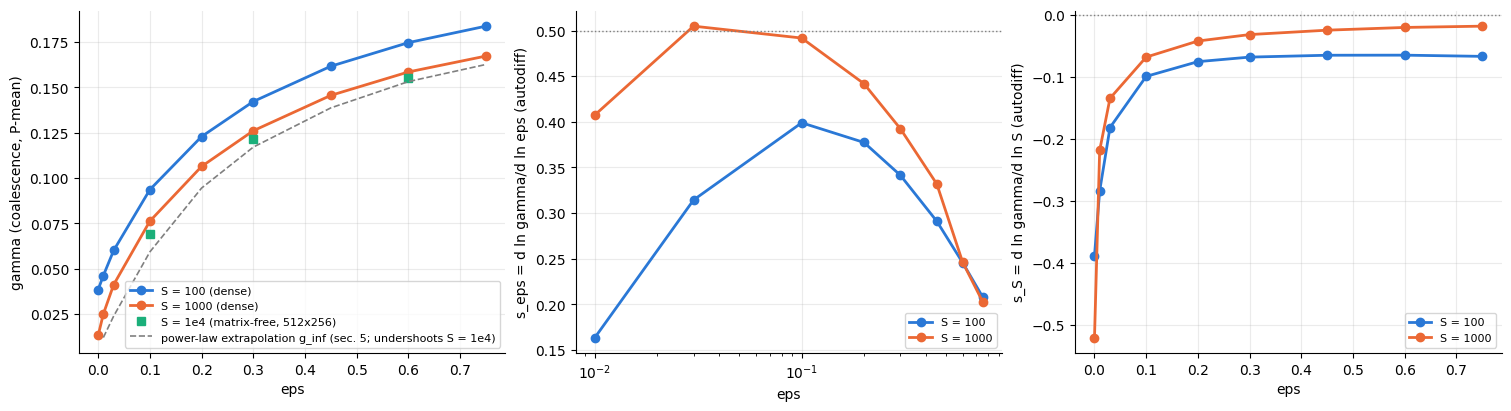

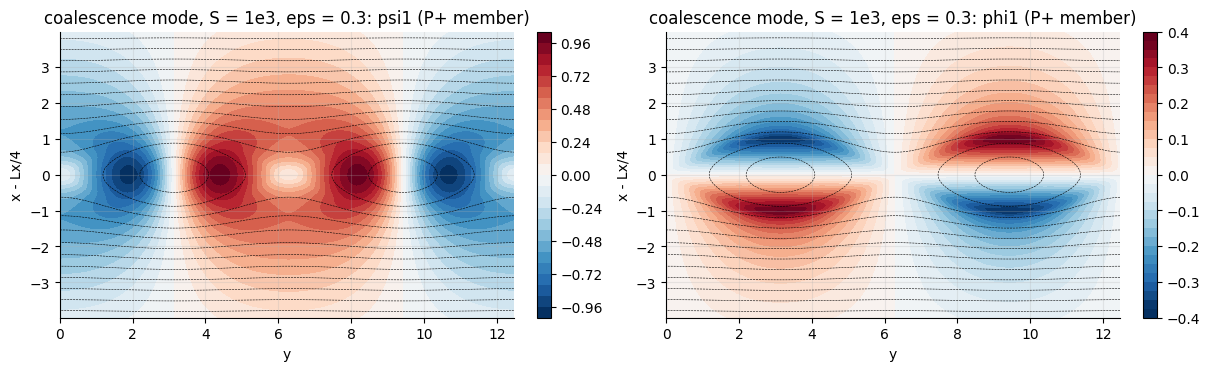

In [7]:
CV = C.conv_table()
fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for i, (S, rows) in enumerate(ET.items()):
    e = np.array([r["eps"] for r in rows]); g = np.array([r["mean"] for r in rows])
    ax[0].plot(e, g, "o-", color=COL[i], label=f"S = {S:g} (dense)")
    ax[1].plot(e[1:], [r["eps"]*r["d_eps"]/r["mean"] for r in rows[1:]], "o-", color=COL[i], label=f"S = {S:g}")
    ax[2].plot(e, [-r["d_eta"]/S/r["mean"] for r in rows], "o-", color=COL[i], label=f"S = {S:g}")
e4 = sorted((k[1], v["mean"]) for k, v in CV.items() if len(k) == 3 and k[0] == 1e4 and k[2] == (512, 256))
if e4:
    ax[0].plot(*zip(*e4), "s", color=COL[2], label="S = 1e4 (matrix-free, 512x256)")
gi = sorted((e, v[0]) for e, v in XT.items() if e > 0 and np.isfinite(v[0]))
ax[0].plot(*zip(*gi), "--", color="0.5", lw=1.2, label="power-law extrapolation g_inf (sec. 5; undershoots S = 1e4)")
ax[0].set_xlabel("eps"); ax[0].set_ylabel("gamma (coalescence, P-mean)"); ax[0].legend(fontsize=8)
ax[1].axhline(0.5, color="0.5", lw=1, ls=":"); ax[1].set_xscale("log")
ax[1].set_xlabel("eps"); ax[1].set_ylabel("s_eps = d ln gamma/d ln eps (autodiff)"); ax[1].legend(fontsize=8)
ax[2].axhline(0, color="0.5", lw=1, ls=":"); ax[2].set_xlabel("eps"); ax[2].set_ylabel("s_S = d ln gamma/d ln S (autodiff)")
ax[2].legend(fontsize=8)
plt.show()
r = [r for r in ET[1e3] if r["eps"] == 0.3][0]
p = C.make_params(1e3, *C.GRID[1e3], Lx=C.LX0); x, y = C.grid(p)
sel = np.abs(x - C.LX0/4) < 4
ps0 = C.psi_chain(x, y, C.LX0, 0.3)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
for a_, f, nm in zip(ax, (r["psi"].astype(float), r["phi"].astype(float)), ("psi1", "phi1")):
    v = np.abs(f[sel]).max()
    m = a_.contourf(y, x[sel] - C.LX0/4, f[sel], 31, cmap="RdBu_r", vmin=-v, vmax=v)
    a_.contour(y, x[sel] - C.LX0/4, ps0[sel], 12, colors="k", linewidths=0.4)
    a_.set_xlabel("y"); a_.set_ylabel("x - Lx/4"); a_.set_title(f"coalescence mode, S = 1e3, eps = 0.3: {nm} (P+ member)")
    plt.colorbar(m, ax=a_)
plt.show()

### 6. The other modes: alternating ($R=-1$) and the chain-period sector ($T=+1$)

**Alternating.** Born degenerate with coalescence at $\epsilon=0$, it splits downwards ($-c\epsilon$, sec. 4) and is stabilised:
the dense $R=-1$ spectra below. Values at round-off ($\lesssim10^{-9}$) are the neutral cluster (flows along flux surfaces), i.e. no
growing alternating mode. The small positive values left at $\epsilon=0.2$ ($S=10^3$: $1.2\times10^{-5}$, $7.8\times10^{-6}$) and the
$1.0\times10^{-9}$ at $\epsilon=0.3$, $S=10^2$ are not resolved growth: on $384\times128$ ($\epsilon=0.2$, $S=10^3$, $P+$) and on $384\times64$ /
$256\times96$ ($\epsilon=0.3$, $S=10^2$) the top of the sector is $0$ (review re-check, 2026-10-03).

**Chain period ($T=+1$).** At $\epsilon\to0$ this sector holds the $k_y=1$ Harris mode, exactly marginal ($\Delta'(1)=0$), so no tearing
is expected, and none is found in three of the four $(R,P)$ sectors. The fourth, $R=P=-1$, grows slowly; its eigenfunction (printed)
is a **relative sliding of the two chains**: $\phi_1$ is almost pure $k_y=0$ (a shear flow between the sheets, zero at the sheet
centres) and $\psi_1$ almost pure chain harmonic $\propto\partial_y\psi_0$ (a rigid translation of each chain along $y$), in
anti-phase between the two sheets. An isolated chain is neutral to translation, so this is the two chains' interaction through the
periodic box -- the $L_x$ scan shows it vanishing as the sheets separate, i.e. **a box artefact, not an instability of the chain**.
Review re-check (2026-10-03, $\epsilon=0.6$, $S=10^3$): $\gamma=1.06\times10^{-2},\ 2.9\times10^{-3},\ 6.5\times10^{-4}$ at $L_x=20,25,30$
(the last on $384\times128$ and $768\times64$ alike), i.e. $\gamma\propto e^{-L_x/4}$, the square root of the $k=1$ inter-chain coupling
$e^{-L_x/2}$; essentially $S$-independent at $L_x=20$ ($8.4,\ 10.6,\ 10.8\times10^{-3}$ at $S=10^2,10^3,10^4$), an ideal interaction.
**The $L_x=40$ entry printed below ($3.7\times10^{-4}$, $512\times64$, with a different eigenfunction) is an under-resolution
artefact**: it is $1.0\times10^{-5}$ on $512\times128$ and exactly $0$ on $1024\times64$ (and $0$ at $L_x=50$).

In [8]:
for S in C.S_LIST:
    print(f"alternating (R = -1) S = {S:g}: eps, P+ / P- tops, mean")
    for r in C.alt_table(S):
        print(f"  eps={r['eps']:5.2f}: {r['lam_p'].real:+.3e} {r['lam_m'].real:+.3e}   mean {r['mean']:+.3e}")
print("\nchain-period sector T = +1, S = 1e3: tops of (R,P) = (+,+) (+,-) (-,+) (-,-)")
for r in C.harm_table():
    print(f"  eps={r['eps']:4.2f}: " + "  ".join(f"{t.real:+.3e}" for t in r["tops"]))
HB = C.harm_box_table()
print("\nthe T+ R- P- mode at eps = 0.6 against the box (fixed dx, ny = 64):")
for Lx, r in sorted(HB.items()):
    phi = r["phi"].astype(float); F = np.abs(np.fft.rfft2(phi))**2
    psi = r["psi"].astype(float); G = np.abs(np.fft.rfft2(psi))**2
    print(f"  Lx = {Lx:4g}: gamma = {r['values'][0].real:+.4e}   phi1 k_y=0 fraction {F[:, 0].sum()/F.sum():.4f}   "
          f"psi1 chain-harmonic (i_ky = 2) fraction {G[:, 2].sum()/G.sum():.4f}")
if len(HB) >= 2:
    Ls = np.array(sorted(HB)); gs = np.array([HB[L]["values"][0].real for L in Ls])
    ok = gs > 1e-12
    if ok.sum() >= 2:
        print("  d ln gamma/d Lx between boxes:", np.round(np.diff(np.log(gs[ok]))/np.diff(Ls[ok]), 4))

alternating (R = -1) S = 100: eps, P+ / P- tops, mean
  eps= 0.00: +3.714e-02 +3.974e-02   mean +3.844e-02
  eps= 0.01: +2.969e-02 +3.214e-02   mean +3.092e-02
  eps= 0.03: +1.862e-02 +2.066e-02   mean +1.964e-02
  eps= 0.10: +4.123e-03 +5.843e-03   mean +4.983e-03
  eps= 0.20: +3.534e-07 +6.733e-05   mean +3.384e-05
  eps= 0.30: +1.535e-15 +1.008e-09   mean +5.039e-10
alternating (R = -1) S = 1000: eps, P+ / P- tops, mean
  eps= 0.00: +1.265e-02 +1.361e-02   mean +1.313e-02
  eps= 0.01: +5.649e-03 +5.977e-03   mean +5.813e-03
  eps= 0.03: +2.418e-03 +2.641e-03   mean +2.529e-03
  eps= 0.10: +5.053e-04 +7.524e-04   mean +6.288e-04
  eps= 0.20: +1.165e-05 +7.797e-06   mean +9.722e-06
  eps= 0.30: +3.071e-15 +1.884e-15   mean +2.478e-15

chain-period sector T = +1, S = 1e3: tops of (R,P) = (+,+) (+,-) (-,+) (-,-)
  eps=0.30: +7.697e-16  +2.886e-15  +5.832e-15  +5.461e-03
  eps=0.60: -1.929e-16  +0.000e+00  +6.475e-15  +1.036e-02
  eps=0.75: +2.116e-11  +1.371e-13  +7.029e-15  +1.264e-02


### 7. Resolution, box, and an independent route

**Grid** ($n_x$ and $n_y$ separately; matrix-free `sector_eigs` beyond the dense reach), **box** ($L_x=20,30,40$ at fixed
$\Delta x$, dense), and the **nonlinear solver** as a route that shares neither the jvp nor any eigensolver: two full nonlinear
runs (`run.block_of_steps`, fixed $dt=0.02$), $x_0$ and $x_0+10^{-9}v$ with $v$ a random vector of the $(-,+,-)$ sector, and the
growth rate of their difference. With $\eta>0$ the base state decays during the run (the frozen-equilibrium assumption is
exactly what the IVP does *not* make), so the clean comparison is at $\eta=0$, where $x_0$ is steady to the image level
$N(x_0)\sim10^{-6}$ (both routes then see the same discrete ideal operator).

In [9]:
CV = C.conv_table()
print("matrix-free P-means (residual on J; seconds for the pair; ARPACK applications):")
for k, v in CV.items():
    tag = f"S={k[0]:g} eps={k[1]} {k[2][0]}x{k[2][1]}" + (f" alpha={k[3]}" if len(k) > 3 else "")
    print(f"  {tag:32s}: {v['mean']:.6f}   res {v['res']:.1e}   {v['seconds']:6.0f} s")
print("\nS = 1e4 (matrix-free) against the S = 1e2/1e3 power-law extrapolation g_inf + (g(1e3) - g_inf) 10^-q (sec. 5):")
g3 = {r["eps"]: r["mean"] for r in ET[1e3]}
for k, v in sorted(CV.items(), key=lambda kv: (len(kv[0]), kv[0][1], kv[0][2])):
    if len(k) == 3 and k[0] == 1e4:
        gi_, q_ = XT[k[1]]
        pred = gi_ + (g3[k[1]] - gi_)*10**(-q_)
        print(f"  eps={k[1]} {k[2][0]}x{k[2][1]}: measured {v['mean']:.6f}, predicted {pred:.6f}, g_inf {gi_:.4f};  "
              f"mean s_S over 1e3..1e4: {np.log(v['mean']/g3[k[1]])/np.log(10):+.4f}")
print("\ndense at the production grid, for comparison:", {(S, r['eps']): round(r['mean'], 6) for S in ET for r in ET[S]
                                                      if (S, r['eps']) in {(1e3, 0.1), (1e3, 0.3), (1e3, 0.6)}})
print("dense 512x64 (nx doubled, ny halved) at small eps, S = 1e3:", {k[1]: round(v, 6) for k, v in C.dconv_table().items()},
      " vs 256x128:", {r['eps']: round(r['mean'], 6) for r in ET[1e3] if r['eps'] in (0.01, 0.03, 0.1)})
BX = C.box_table()
r03 = [r for r in ET[1e3] if r["eps"] == 0.3][0]
print(f"\nbox, S = 1e3, eps = 0.3 (dx = 0.078, ny = 128): Lx = 20: {r03['lam_p'].real:.6f} {r03['lam_m'].real:.6f} mean {r03['mean']:.6f}")
for Lx, v in sorted(BX.items()):
    print(f"                                          Lx = {Lx:g}: {v['lam_p'].real:.6f} {v['lam_m'].real:.6f} mean {v['mean']:.6f}")
print("\nindependent route (nonlinear solver, 256x128, eps = 0.3, sector (-,+,-)):")
for S in C.IVP_S:
    iv = C.ivp_point(S=S, compute=False)
    dn = C.dense_point(S, C.IVP["eps"], C.IVP["signs"], grid_=C.IVP["grid"], sens=(), compute=False)
    t, d = iv["t"], iv["delta"]
    sl = np.diff(np.log(d))/np.diff(t)
    late = sl[t[1:] > 60]
    print(f"  S = {S:g}: IVP slope over t in {C.IVP['window']}: {iv['gamma']:.6f}; local slopes for t > 60: "
          f"{late.min():.5f}..{late.max():.5f};  frozen-x0 eigenvalue {dn['values'][0].real:.6f};  "
          f"ratio {iv['gamma']/dn['values'][0].real:.5f}")

matrix-free P-means (residual on J; seconds for the pair; ARPACK applications):
  S=1000 eps=0.1 256x128          : 0.076222   res 1.3e-12      282 s
  S=1000 eps=0.1 512x128          : 0.076281   res 4.6e-13      943 s
  S=1000 eps=0.1 256x256          : 0.076240   res 7.3e-13      816 s
  S=1000 eps=0.1 512x256          : 0.076244   res 5.7e-13     1609 s
  S=1000 eps=0.3 256x128          : 0.126095   res 4.0e-12      162 s
  S=1000 eps=0.3 512x128          : 0.126265   res 8.8e-13      525 s
  S=1000 eps=0.3 256x256          : 0.126004   res 5.6e-13      501 s
  S=1000 eps=0.3 512x256          : 0.126213   res 5.3e-13     1150 s
  S=1000 eps=0.6 256x128          : 0.158551   res 7.3e-12      148 s
  S=1000 eps=0.6 512x256          : 0.158496   res 1.1e-12     1125 s
  S=10000 eps=0.3 512x256         : 0.121811   res 1.1e-12     1073 s
  S=10000 eps=0.3 768x256         : 0.121890   res 6.7e-13     1976 s
  S=10000 eps=0.3 512x384         : 0.121822   res 3.9e-13     1240 s
  S=10000 

### 7b. Independent route 2: a single-sheet eigencode (review, 2026-10-03)

Written by the reviewer, sharing no code with taranis or this module (`scratchpad item3_review/indep/fadeev.py`, not in the repo):
linearised incompressible 2D RMHD about the **isolated** chain $\ln(\cosh x+\epsilon\cos y)$ (one sheet, conducting walls at $|x|=25$,
no images, no pair), frozen equilibrium, $\nu=0$; $x$: 4th-order finite differences on a $\sinh$-mapped grid; $y$: Galerkin on the
half-integer harmonics $k_n=n/2$ ($n$ odd, the $T=-1$ sector) with $\psi_1\sim\cos$, $\phi_1\sim\sin$ ($R=+1$), or the full cos+sin basis for
both fields with flow; generalised problem $\lambda\,\mathrm{diag}(I,\nabla^2)u=Au$ by sparse shift-invert. Checks: $\epsilon=0$ gives
$0.0131257$ (the $L_x=60$ 1D mean above, $0.01312572$); walls at 25 vs 40 agree to $10^{-7}$.

| $S$ | $\epsilon$ | $\alpha$ | independent | taranis (this notebook) |
|---|---|---|---|---|
| $10^3$ | 0.1 | 0 | 0.076236 | 0.076222 (256x128), 0.076244 (512x256) |
| $10^3$ | 0.3 | 0 | **0.126205** ($n_x$ 800--1600, $K$ 24--48: $\pm10^{-6}$ at $K\ge40$) | 0.126095 (256x128), **0.126213** (512x256); members 0.1225 / 0.1299 |
| $10^3$ | 0.6 | 0 | 0.158450 | 0.158551 (256x128), 0.158496 (512x256) |
| $10^3$ | 0.75 | 0 | 0.167100 | 0.167320 (256x128) |
| $10^4$ | 0.3 | 0 | 0.121908 | 0.121811 (512x256), 0.121890 (768x256) |
| $10^4$ | 0.1 | 0 | 0.069548 | 0.069363 (512x256) |
| $10^3$ | 0.3 | 0.6 | 0.084650 | 0.082863 (256x128), 0.084036 (512x256), 0.084316 (768x256; review runs) |
| $10^3$ | 0.3 | 0.8 | 0.050545 | 0.047716 (256x128), 0.049251 (512x256) |
| $10^3$ | 0.3 | 0.9 | 0.028512 | 0.025620 (256x128) |

Small-$\epsilon$ local exponent $s_\epsilon$ (5% steps in $\epsilon$): $\epsilon=0.03$: $0.500,\ 0.630,\ 0.701$ and $\epsilon=0.1$:
$0.505,\ 0.583,\ 0.605$ at $S=10^3,10^4,10^5$ -- the $S=10^3$ value $\simeq1/2$ is not an $S$-independent law.

### 8. Field-aligned flow $\phi_0=\alpha\psi_0$

Steady for any $\alpha$; sectors $(T,PR,XR)=(-,\pm,+)$ (coalescence has $XR=+1$; at $\alpha=0$ they are the $R=+1$, $P=\pm1$ sectors,
equal to $10^{-13}$). $\epsilon=0.3$; dense at the production grids; $d\gamma/d\alpha$ from the state direction
$dx_0=(\psi_0,0)$, zero at $\alpha=0$ by the $R$ symmetry ($R$ maps $\alpha\to-\alpha$ inside each $(PR,XR)$ sector; gated to $10^{-10}$).

Linearising about $\phi_0=\alpha\psi_0$ with $\chi=\phi_1-\alpha\psi_1$: $\partial_t\psi_1=\{\psi_0,\chi\}$ and
$\partial_t\nabla^2(\chi+\alpha\psi_1)=(1-\alpha^2)\mathcal L\psi_1-\alpha\mathcal L\chi$, $\mathcal L f=\{\psi_0,\nabla^2f\}+\{f,J_0\}$
the static operator. The $(1-\alpha^2)$ in front of the static drive suggests $\gamma\propto1-\alpha^2$, but the $\alpha$ terms
($-\alpha\mathcal L\chi$ and $\alpha\partial_t\nabla^2\psi_1$) do not cancel for a 2D $\psi_0$, so no exact law follows; the
comparison below is empirical. **Resolution:** the dense numbers below are at the production grids and run low at large $\alpha$; the
resolved ratios are in sec. 8b. The suppression to zero at $\alpha\to1$ is required: $\alpha=\pm1$ are Alfvénic states, exact
nonlinear solutions.

S = 1000, eps = 0.3: alpha | gamma (PR+, PR-) | mean | /gamma(0) | 1-alpha^2 | sqrt(1-alpha^2) | d ln gamma/d alpha (autodiff) | -2 alpha/(1-alpha^2) | s_S | max |Im|
  0.00 | 0.122136 0.130055 | 0.126095 | 1.0000 | 1.0000 | 1.0000 | +0.0000 | -0.0000 | -0.0319 | 0.0e+00
  0.20 | 0.117533 0.125270 | 0.121402 | 0.9628 | 0.9600 | 0.9798 | -0.3878 | -0.4167 | -0.0338 | 0.0e+00
  0.40 | 0.103582 0.110726 | 0.107154 | 0.8498 | 0.8400 | 0.9165 | -0.8942 | -0.9524 | -0.0400 | 0.0e+00
  0.60 | 0.079869 0.085857 | 0.082863 | 0.6571 | 0.6400 | 0.8000 | -1.7831 | -1.8750 | -0.0526 | 0.0e+00
  0.80 | 0.045734 0.049699 | 0.047716 | 0.3784 | 0.3600 | 0.6000 | -4.2942 | -4.4444 | -0.0765 | 0.0e+00
  0.90 | 0.024389 0.026851 | 0.025620 | 0.2032 | 0.1900 | 0.4359 | -9.2863 | -9.4737 | -0.0995 | 0.0e+00
S = 100, eps = 0.3: alpha | gamma (PR+, PR-) | mean | /gamma(0) | 1-alpha^2 | sqrt(1-alpha^2) | d ln gamma/d alpha (autodiff) | -2 alpha/(1-alpha^2) | s_S | max |Im|
  0.00 | 0.138594 0.145865 | 0.142230

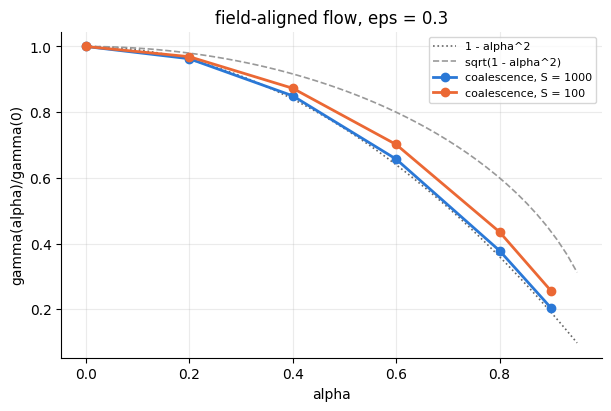

In [10]:
AT = {S: C.alpha_table(S=S) for S in C.ALPHA_S}
for S, rows in AT.items():
    if not rows:
        continue
    g0 = rows[0]["mean"]
    print(f"S = {S:g}, eps = {C.EPS_ALPHA}: alpha | gamma (PR+, PR-) | mean | /gamma(0) | 1-alpha^2 | sqrt(1-alpha^2) | "
          f"d ln gamma/d alpha (autodiff) | -2 alpha/(1-alpha^2) | s_S | max |Im|")
    for r in rows:
        a_ = r["alpha"]
        print(f"  {a_:4.2f} | {r['lam_p'].real:.6f} {r['lam_m'].real:.6f} | {r['mean']:.6f} | {r['mean']/g0:.4f} | {1-a_*a_:.4f} | "
              f"{np.sqrt(1-a_*a_):.4f} | {r['d_alpha']/r['mean']:+.4f} | {-2*a_/(1-a_*a_):+.4f} | {-r['d_eta']/S/r['mean']:+.4f} | {r['im']:.1e}")
CVA = {k: v for k, v in C.conv_table().items() if len(k) == 4}
g0 = {1e3: AT[1e3][0]["mean"], 1e4: [v["mean"] for k, v in C.conv_table().items() if k == (1e4, 0.3, (512, 256))][0]}
print("\nmatrix-free 512x256 checks (gamma(0) at the same S and grid where available):")
for k, v in CVA.items():
    S, e, g, a_ = k
    dense = [r["mean"] for r in AT.get(S, []) if r["alpha"] == a_]
    ref = g0[S] if S == 1e4 else [v2["mean"] for k2, v2 in C.conv_table().items() if k2 == (1e3, 0.3, (512, 256))][0]
    print(f"  S={S:g} alpha={a_}: {v['mean']:.6f} (dense 256x128: {dense[0] if dense else float('nan'):.6f});  "
          f"gamma(alpha)/gamma(0) = {v['mean']/ref:.4f}  vs 1-alpha^2 = {1-a_*a_:.4f}")
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
aa = np.linspace(0, 0.95, 50)
ax.plot(aa, 1 - aa**2, ":", color="0.4", lw=1.2, label="1 - alpha^2")
ax.plot(aa, np.sqrt(1 - aa**2), "--", color="0.6", lw=1.2, label="sqrt(1 - alpha^2)")
for i, (S, rows) in enumerate(AT.items()):
    if rows:
        ax.plot([r["alpha"] for r in rows], [r["mean"]/rows[0]["mean"] for r in rows], "o-", color=COL[i], label=f"coalescence, S = {S:g}")
ax.set_xlabel("alpha"); ax.set_ylabel("gamma(alpha)/gamma(0)"); ax.legend(fontsize=8)
ax.set_title(f"field-aligned flow, eps = {C.EPS_ALPHA}")
plt.show()

### 8b. Flow, resolved

$\gamma(\alpha)/\gamma(0)$ at $\epsilon=0.3$ from the independent single-sheet code (sec. 7b), converged in $x$ and $y$ to $\lesssim5\times10^{-4}$:

| $\alpha$ | $S=10^2$ | $S=10^3$ | $S=10^4$ | $1-\alpha^2$ | production $S=10^3$ |
|---|---|---|---|---|---|
| 0.2 | | 0.9642 | | 0.96 | 0.9628 |
| 0.4 | | 0.8558 | | 0.84 | 0.8498 |
| 0.6 | 0.7050 | 0.6707 | 0.6528 | 0.64 | 0.6571 |
| 0.8 | 0.4429 | 0.4005 | 0.3746 | 0.36 | 0.3784 |
| 0.9 | 0.2633 | 0.2259 | | 0.19 | 0.2032 |

The suppression is weaker than $1-\alpha^2$ at every $S$ reached and approaches it from above as $S$ grows; at $S=10^3$ the production
grid's apparent closeness to $1-\alpha^2$ is partly its own under-resolution. taranis converges towards these values ($\alpha=0.6$:
$0.08286\to0.08404\to0.08432$ at $n_x=256,512,768$, against $0.08465$).

### 9. The autodiff payoff, checked: sensitivities against eigenvalue finite differences

Central differences of dense sector eigenvalues at $h$ and $h/2$ ($\eta$: relative steps through the overrides seam), Richardson
-extrapolated ($O(h^4)$), against `eigenvalue_sensitivity` with `dj_operator` along $dx_0=\partial_\epsilon x_0$,
`dparams={"diss": (0, 1)}` and $dx_0=(\psi_0,0)$. Production grid ($256\times128$, $S=10^3$), $P=+1$ member.

In [11]:
for r in C.fd_table():
    b, f = r["base"], r["fd"]
    for k in ("eps", "eta", "alpha"):
        if f"d_{k}" not in b or f"fd_{k}_{C.FD_H[0]:g}" not in f:
            continue
        f1, f2 = complex(f[f"fd_{k}_{C.FD_H[0]:g}"]), complex(f[f"fd_{k}_{C.FD_H[1]:g}"])
        ext = (4*f2 - f1)/3
        ad = complex(b[f"d_{k}"])
        print(f"  eps={r['eps']} alpha={r['alpha']}: d lam/d {k:5s} autodiff {ad.real:+.10f}  FD(h) {f1.real:+.10f}  FD(h/2) {f2.real:+.10f}  "
              f"Richardson {ext.real:+.10f}  rel. diff {abs(ext - ad)/abs(ad):.1e}   kappa {float(b['kappa_' + k]):.2f}")

  eps=0.3 alpha=0.0: d lam/d eps   autodiff +0.1490184414  FD(h) +0.1490166388  FD(h/2) +0.1490179890  Richardson +0.1490184391  rel. diff 1.6e-08   kappa 6.37
  eps=0.3 alpha=0.0: d lam/d eta   autodiff +4.2584551463  FD(h) +4.2584566330  FD(h/2) +4.2584555177  Richardson +4.2584551459  rel. diff 9.1e-11   kappa 6.37
  eps=0.1 alpha=0.0: d lam/d eps   autodiff +0.4034175605  FD(h) +0.4031754616  FD(h/2) +0.4033569477  Richardson +0.4034174431  rel. diff 2.9e-07   kappa 7.01
  eps=0.1 alpha=0.0: d lam/d eta   autodiff +5.7659363681  FD(h) +5.7659406086  FD(h/2) +5.7659374278  Richardson +5.7659363675  rel. diff 1.1e-10   kappa 7.01
  eps=0.3 alpha=0.6: d lam/d eps   autodiff +0.0792435912  FD(h) +0.0792411111  FD(h/2) +0.0792429695  Richardson +0.0792435890  rel. diff 2.7e-08   kappa 14.53
  eps=0.3 alpha=0.6: d lam/d eta   autodiff +4.4676700105  FD(h) +4.4676714811  FD(h/2) +4.4676703860  Richardson +4.4676700209  rel. diff 2.3e-09   kappa 14.53
  eps=0.3 alpha=0.6: d lam/d alpha aut

### 10. Literature

* **Finn & Kaw 1977**, "Coalescence instability of magnetic islands", Phys. Fluids **20**, 72 (the 1976 Princeton report PPPL-1226
  of the same title was read, OSTI 7364034). Ideal incompressible MHD of the Fadeev chain $\psi_0=\ln(\cosh kx+\epsilon\cos ky)$.
  Their mode is ours: $\phi=\sum_l\phi_l(x)\sin[(2l-1)ky/2]$ with $\phi_l$ odd in $x$ -- period doubling ($T=-1$), $\phi$ odd about the
  X-point ($R=+1$) and tearing parity ($XR=+1$), the two islands approaching each other. A one-harmonic normal-mode analysis gave
  **no** instability; an energy-principle estimate gave instability for $\epsilon$ not too small, and they **conjectured a threshold**
  $\epsilon_0>0$. No growth rates are given.
* **Pritchett & Wu 1979**, "Coalescence of magnetic islands", Phys. Fluids **22**, 2140: numerical growth rates down to $\epsilon\to0$,
  refuting the threshold (as summarised by Liao, Lin & Zhu, below; the paper itself was not obtained, so no number of theirs is compared).
* **Bondeson 1983**, "Linear analysis of the coalescence instability", Phys. Fluids **26**, 1275: incompressible ideal MHD; for small
  island width $w$ the growth rate is $\propto w^{3/2}$, i.e. $\gamma\propto\epsilon^{3/4}$ (abstract; text not obtained). Our resistive
  local exponent $s_\epsilon$ at small $\epsilon$ is $0.5$ at $S=10^3$ and climbs towards $3/4$ with $S$ (0.63, 0.70 at $S=10^4,10^5$,
  $\epsilon=0.03$, sec. 7b) -- consistent with that ideal law being approached, not yet a test of its coefficient.
* **Liao, Lin & Zhu**, "On the stability and instability of Kelvin-Stuart cat's-eye flows", arXiv:2304.00264 (Invent. Math. 2026): the
  first rigorous proof of linear coalescence instability (double-periodic perturbations) for the whole family -- the reason no threshold
  is found here.
* **Bhattacharjee, Brunel & Tajima 1983**, Phys. Fluids **26**, 3332 -- the nonlinear, reconnection-driven phase; not used.
* **Normalisation.** All of these use $k=1$ (our chain), $B\to\tanh$ asymptotically and $\rho=1$, i.e. our Alfvén units, so a future
  comparison with Pritchett & Wu's or Bondeson's tabulated rates needs no rescaling.


### 11. Caveats

* **Frozen equilibrium.** At $\eta>0$ the chain diffuses ($\eta\nabla^2\psi_0\ne0$); $J=L+N'(x_0)$ is the instantaneous linearisation,
  as in every 1D notebook. The nonlinear-solver route shows the size of that assumption directly: at $S=10^4$ its growth rate falls
  below the frozen eigenvalue by the drift of the base state (sec. 7), at $\eta=0$ the two agree. Anything with $\gamma=O(\eta)$ is not meaningful
  (the $T=+1$ remnant once printed at $L_x=40$ was in any case an under-resolution artefact, sec. 6).
* **$S$ range.** A uniform spectral grid must resolve the reconnection layer at the X-points in both $x$ and $y$: production
  $S\le10^3$ (dense, converged to $2.5\times10^{-3}$), $S=10^4$ only at a few $\epsilon$ matrix-free (sec. 7), and the
  $\epsilon=0$ splitting to $S=10^5$ (where only $n_y=16$ is needed). $S\gtrsim10^5$ at finite $\epsilon$ is out of reach without
  non-uniform resolution.
* **Two sheets.** Every number is the mean of the two pair members ($P=\pm1$) at $L_x=20$ -- an estimator of the isolated chain, not an
  eigenvalue; the members are $\pm3$--$4\%$ apart at $L_x=20$. The box check is sec. 7, the no-image check sec. 7b.
* **Flow at large $\alpha$** is under-resolved on the production grid (2--10% low at $\alpha=0.6$--$0.9$, sec. 8b).
* **The $(1-\alpha^2)$ comparison** is empirical (sec. 8 shows why no exact law follows).
* **Literature** not verified (sec. 10).